# n-pulse: b1_yolo11n_d1 training on Colab (T4 GPU, YOLO11n, 6 classes, archived log)

**Before running:** *Runtime > Change runtime type > T4 GPU*. On Google Drive you need:
- `MyDrive/npulse/training_code.zip` (from `bash training/colab/make_code_zip.sh`, re-made after each code change)
- `MyDrive/npulse/data/<dataset>.zip` (from `bash training/colab/make_data_zip.sh <dataset>`, uploaded once)

Runs are written to `MyDrive/npulse/runs/<RUN_NAME>/`. Numbers shown here are for monitoring only:
the reported metrics come from `eval.py` run **locally** (see `training/README.md`).

## 1. Parameters
One run per notebook execution. `EXTRA_ARGS` is passed as-is to `train.py` (e.g. `"--fraction 0.1"`).

In [10]:
RUN_NAME   = "b1_yolo11n_d1"
DATA_ZIPS  = ["openimages6.zip"]   # in MyDrive/npulse/data/, unzipped into training/datasets/
EPOCHS     = 30
IMGSZ      = 416
BATCH      = 32
PATIENCE   = 10
EXTRA_ARGS = "--model yolo11n.pt"

## 2. Mount Google Drive

In [11]:
from google.colab import drive
drive.mount("/content/drive")

import os
DRIVE = "/content/drive/MyDrive/EPFL/Association_Npulse_CV"
for f in ["training_code.zip"] + [f"data/{z}" for z in DATA_ZIPS]:
    print(("ok      " if os.path.exists(f"{DRIVE}/{f}") else "MISSING ") + f"{DRIVE}/{f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ok      /content/drive/MyDrive/EPFL/Association_Npulse_CV/training_code.zip
ok      /content/drive/MyDrive/EPFL/Association_Npulse_CV/data/openimages6.zip


## 3. Code: unzip `training_code.zip` into `/content/ARM-SOFT-Grasping/`
The zip is copied to the local disk first (reading many small files from Drive is slow).

In [12]:
import pathlib, shutil, zipfile
REPO = pathlib.Path("/content/ARM-SOFT-Grasping")
REPO.mkdir(parents=True, exist_ok=True)
shutil.copy(f"{DRIVE}/training_code.zip", "/content/training_code.zip")
zipfile.ZipFile("/content/training_code.zip").extractall(REPO)
print(sorted(p.name for p in (REPO / "training").iterdir()))

['README.md', '__init__.py', '__pycache__', 'colab', 'compare_runs.py', 'data', 'datasets', 'decisions.md', 'eval.py', 'live_test.py', 'paths.py', 'register_in_studio.py', 'requirements.txt', 'runs', 'tests', 'train.py']


*Optional, instead of step 3, once the branch is pushed:* get the code with git.

In [13]:
# !git clone --depth 1 --branch multiclass-detection https://github.com/<owner>/ARM-SOFT-Grasping.git /content/ARM-SOFT-Grasping
# import pathlib; REPO = pathlib.Path("/content/ARM-SOFT-Grasping")

## 4. Data: copy each zip to the local disk, unzip into `training/datasets/`
Training reads images from the local disk, never from Drive.

In [14]:
DATASETS = REPO / "training" / "datasets"
DATASETS.mkdir(parents=True, exist_ok=True)
for z in DATA_ZIPS:
    local = f"/content/{z}"
    if not os.path.exists(local):
        shutil.copy(f"{DRIVE}/data/{z}", local)
    zipfile.ZipFile(local).extractall(DATASETS)
for d in sorted(DATASETS.iterdir()):
    print(d.name, {s: len(list((d / "images" / s).glob("*"))) for s in ("train", "val", "test")})

openimages6 {'train': 2080, 'val': 446, 'test': 445}


## 5. Install Ultralytics (same version as locally) and check the GPU

In [15]:
!pip install -q ultralytics==8.4.163
import torch, ultralytics
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| CUDA", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - set Runtime > T4 GPU")

ultralytics 8.4.163 | torch 2.11.0+cu130 | CUDA 13.0
GPU: Tesla T4


## 6. Train
`training/runs/detect` is a link to `MyDrive/npulse/runs`, so Ultralytics writes `last.pt` / `best.pt`
and `results.csv` straight to Drive after every epoch: a disconnected session loses at most one epoch.

In [16]:
RUNS_DRIVE = pathlib.Path(DRIVE) / "runs"
RUNS_DRIVE.mkdir(parents=True, exist_ok=True)
detect = REPO / "training" / "runs" / "detect"
detect.parent.mkdir(parents=True, exist_ok=True)
if not detect.is_symlink():
    shutil.rmtree(detect, ignore_errors=True)
    detect.symlink_to(RUNS_DRIVE, target_is_directory=True)
if (RUNS_DRIVE / RUN_NAME).exists():
    print(f"WARNING: {RUNS_DRIVE / RUN_NAME} exists -> Ultralytics will create a new name; "
          "change RUN_NAME, pass --exist-ok in EXTRA_ARGS, or use the resume cell below.")

%cd {REPO}
!python training/train.py --device 0 --name {RUN_NAME} --epochs {EPOCHS} --imgsz {IMGSZ} --batch {BATCH} --patience {PATIENCE} {EXTRA_ARGS}

/content/ARM-SOFT-Grasping
New https://pypi.org/project/ultralytics/8.4.197 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.163 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ARM-SOFT-Grasping/training/runs/openimages6.resolved.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01

*Optional, after a disconnection:* re-run steps 1–5, then resume from the last checkpoint on Drive.

In [17]:
# from ultralytics import YOLO
# YOLO(f"{RUNS_DRIVE}/{RUN_NAME}/weights/last.pt").train(resume=True)

## 7. Training curves and final val metrics (monitoring only)

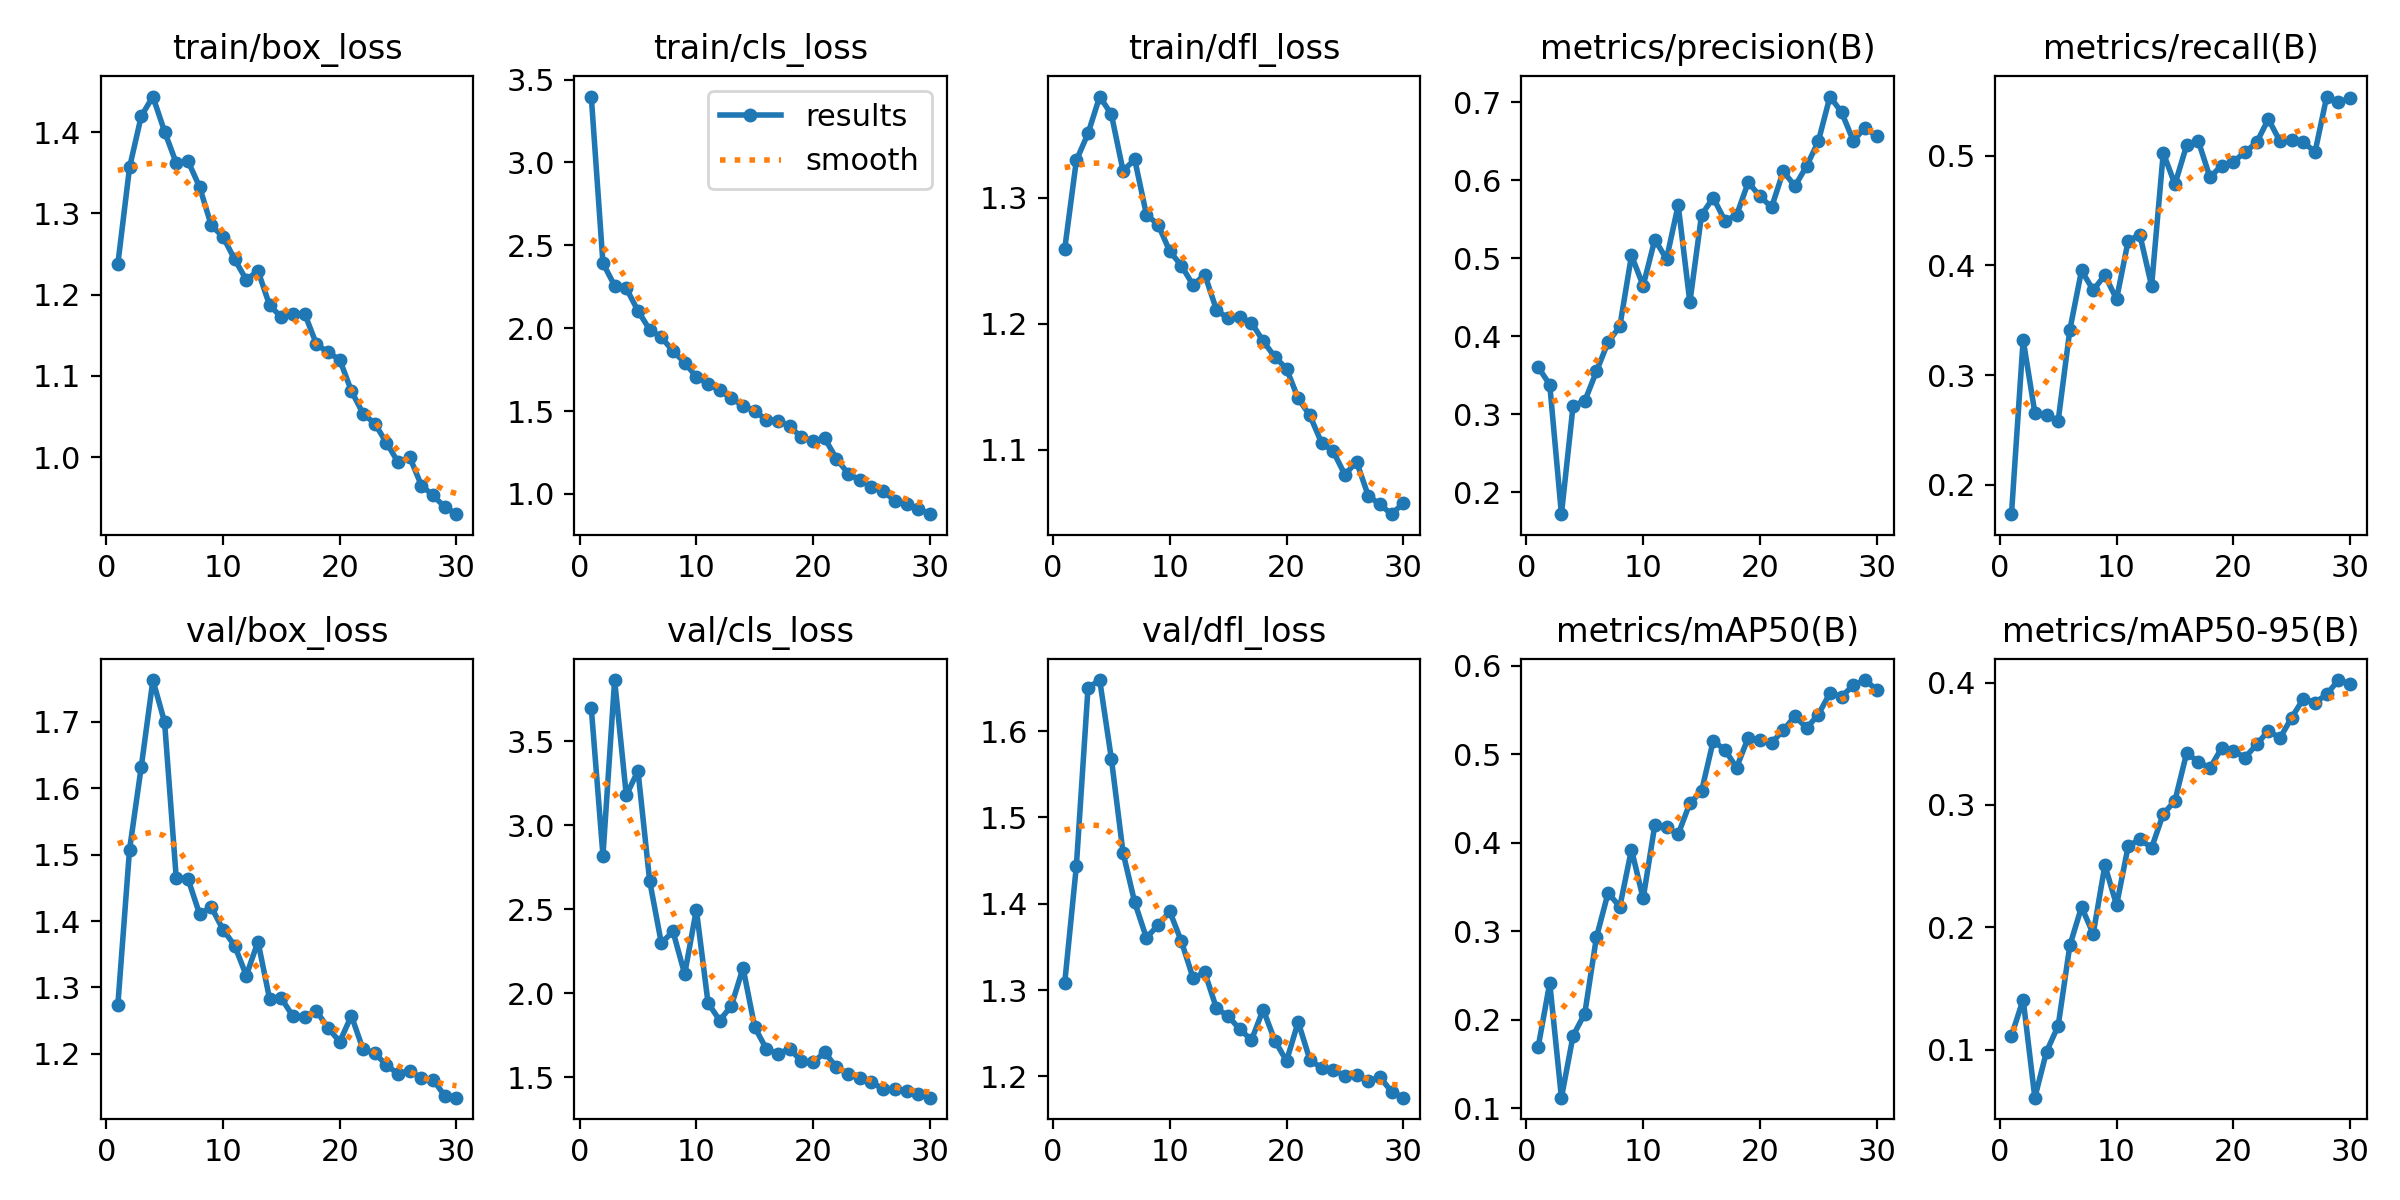

last epochs:
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    28               0.65043            0.55400           0.57799              0.39030
    29               0.66731            0.54882           0.58393              0.40201
    30               0.65622            0.55261           0.57306              0.39909

best val mAP50 epoch:
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    29               0.66731            0.54882           0.58393              0.40201

Next: download /content/drive/MyDrive/EPFL/Association_Npulse_CV/runs/b1_yolo11n_d1 into training/runs/detect/b1_yolo11n_d1/ and run eval.py locally.


In [18]:
import pandas as pd
from IPython.display import Image, display
run = RUNS_DRIVE / RUN_NAME
display(Image(filename=str(run / "results.png"), width=1000))
df = pd.read_csv(run / "results.csv")
df.columns = [c.strip() for c in df.columns]
cols = ["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]
print("last epochs:"); print(df[cols].tail(3).to_string(index=False))
print("\nbest val mAP50 epoch:"); print(df.loc[[df["metrics/mAP50(B)"].idxmax()], cols].to_string(index=False))
print(f"\nNext: download {run} into training/runs/detect/{RUN_NAME}/ and run eval.py locally.")